
# 07 — Alternative Forecasting Models: Random Forest

## 1. Introduction

This notebook investigates whether a nonlinear machine learning model can improve forecasts of daily electricity consumption in Basel-Stadt compared with the baseline and linear regression models developed in Notebooks 05 and 06.

**Research question:** How accurately can we predict next-day electricity consumption (MWh/day) using information available by 12:00 on the preceding day?

### Why Random Forest?

Linear regression models electricity consumption as an additive combination of explanatory variables. However, electricity demand may involve nonlinear relationships and interactions between temperature, historical consumption, weekdays and holidays.

A Random Forest Regressor combines predictions from multiple decision trees and can represent such relationships without requiring us to specify every interaction in advance.

### Methodology

- **Target:** Daily electricity consumption in MWh/day.
- **Predictors:** Historical consumption lags, archived weather forecasts and calendar variables.
- **Availability rule:** Only consumption lags `lag_5` and older are permitted.
- **Initial training period:** 2018–2024.
- **Validation:** 12 monthly chronological folds in 2025.
- **Refitting:** Once per month, using target observations up to the first day of the validation month minus five calendar days.
- **Primary metric:** MAE (MWh/day).
- **Secondary metric:** RMSE (MWh/day).
- **Additional diagnostic:** Mean signed prediction error.
- **Final holdout:** January–October 2026, reserved for later evaluation.

The Random Forest will initially use an expanding training window. The expanding-versus-rolling comparison will be conducted in Notebook 08.

All model selection will rely on the 2025 validation period. The 2026 holdout will not be used.


## 2. Import Libraries and set Paths

In [14]:
# Import libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# Find the repository root
def find_repo_root(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / "data" / "processed" / "features.csv").exists():
            return folder
    raise FileNotFoundError(
        "Cannot find data/processed/features.csv. "
        "Check your working directory."
    )

ROOT = find_repo_root(Path.cwd().resolve())

FEATURES_PATH = ROOT / "data" / "processed" / "features.csv"
TABLE_DIR = ROOT / "output" / "tables"
FIG_DIR = ROOT / "output" / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Shared methodology
TRAIN_START = pd.Timestamp("2018-01-01")
VALIDATION_MONTHS = pd.period_range(
    "2025-01", "2025-12", freq="M"
)
MIN_LAG = 5

print("Repository root:", ROOT)
print("Features file:", FEATURES_PATH)
print("Number of validation months:", len(VALIDATION_MONTHS))


Repository root: /Users/laramileto/Documents/HSG/5° semestre /Workshop fundamentals DSF/group project/group_project/DSF_forecasting_electricity_consumption_Basel
Features file: /Users/laramileto/Documents/HSG/5° semestre /Workshop fundamentals DSF/group project/group_project/DSF_forecasting_electricity_consumption_Basel/data/processed/features.csv
Number of validation months: 12


## 3. Load and verify the dataset

In [15]:
df = pd.read_csv(
    FEATURES_PATH,
    parse_dates=["date"]
).sort_values("date").reset_index(drop=True)

# Essential structural checks
required_columns = [
    "date",
    "period",
    "consumption_mwh",
    "lag_5",
    "lag_6",
    "lag_7",
    "lag_14",
    "lag_21",
    "lag_28",
    "lag_mean_5_11",
    "heating_degrees",
    "cooling_degrees",
    "forecast_precipitation",
    "weekday",
    "month",
    "is_holiday",
    "is_christmas_period",
    "lag_7_is_holiday",
    "lag_14_is_holiday",
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

assert df["date"].is_unique, "Duplicate dates found"

# Display the dataset structure
print("Dataset shape:", df.shape)

print(
    "Date range:",
    df["date"].min().date(),
    "to",
    df["date"].max().date()
)

print("\nObservations by period:")
display(df.groupby("period")["date"].agg(
    first="min",
    last="max",
    days="count"
))

print("\nMissing values:")
display(df[required_columns].isna().sum().to_frame("missing"))

# Restrict the working dataset to development data.
# The 2026 holdout remains reserved for Person 4.
development_df = df[
    df["date"] < pd.Timestamp("2026-01-01")
].copy()

print("\nDevelopment observations:", len(development_df))


Dataset shape: (3226, 25)
Date range: 2018-01-01 to 2026-10-31

Observations by period:


,first,last,days
period,,,
test,2026-01-01,2026-10-31,304
train,2018-01-01,2024-12-31,2557
validation,2025-01-01,2025-12-31,365



Missing values:


,missing
date,0
period,0
consumption_mwh,0
lag_5,0
lag_6,0
lag_7,0
lag_14,0
lag_21,0
lag_28,0
lag_mean_5_11,0



Development observations: 2922



## 4. Choice of explanatory variables

To ensure a fair comparison with Notebook 06, the Random Forest uses the same explanatory variables as the OLS model with weather forecasts.

The predictors belong to four groups:

1. **Historical electricity consumption:** lagged consumption values from at least five days before the target date, plus the recent historical consumption average.
2. **Weather forecasts:** heating degrees, cooling degrees, and forecast precipitation.
3. **Categorical calendar variables:** weekday and month.
4. **Binary calendar variables:** public holidays, Christmas period, and holiday indicators for lagged days.

The weather predictors are historical forecasts, not realized weather observations.

We exclude the target variable, date, period labels and baseline prediction from the explanatory variables.

Random Forest can model nonlinear relationships and interactions without explicitly adding polynomial or interaction terms.

No predictors are selected using the 2026 test data.


In [16]:
# Same feature groups as OLS with weather

TARGET = "consumption_mwh"

LAG_FEATURES = [
    "lag_5",
    "lag_6",
    "lag_7",
    "lag_14",
    "lag_21",
    "lag_28",
    "lag_mean_5_11",
]

WEATHER_FEATURES = [
    "heating_degrees",
    "cooling_degrees",
    "forecast_precipitation",
]

CATEGORICAL_FEATURES = [
    "weekday",
    "month",
]

BINARY_FEATURES = [
    "is_holiday",
    "is_christmas_period",
    "lag_7_is_holiday",
    "lag_14_is_holiday",
]

FEATURES = (
    LAG_FEATURES
    + WEATHER_FEATURES
    + CATEGORICAL_FEATURES
    + BINARY_FEATURES
)

FORBIDDEN_FEATURES = [
    "date",
    "period",
    "consumption_mwh",
    "baseline",
    "baseline_uses_fallback",
]

assert len(FEATURES) == len(set(FEATURES))
assert not set(FEATURES).intersection(FORBIDDEN_FEATURES)
assert all(col in development_df.columns for col in FEATURES)

print("Number of predictors:", len(FEATURES))

print("\nConsumption features:", LAG_FEATURES)
print("Weather features:", WEATHER_FEATURES)
print("Categorical features:", CATEGORICAL_FEATURES)
print("Binary features:", BINARY_FEATURES)


Number of predictors: 16

Consumption features: ['lag_5', 'lag_6', 'lag_7', 'lag_14', 'lag_21', 'lag_28', 'lag_mean_5_11']
Weather features: ['heating_degrees', 'cooling_degrees', 'forecast_precipitation']
Categorical features: ['weekday', 'month']
Binary features: ['is_holiday', 'is_christmas_period', 'lag_7_is_holiday', 'lag_14_is_holiday']



## 5. Random Forest model and preprocessing

A Random Forest Regressor combines multiple decision trees to predict electricity consumption.

Individual trees recursively split observations according to their predictor values. Combining many trees can reduce the instability of a single decision tree.

Unlike linear regression, Random Forest can capture nonlinear relationships and interactions, for example between temperature, holidays and historical electricity consumption.

### Preprocessing

- Numerical features: missing values are imputed using the median of the training data.
- Weekday and month: one-hot encoded as categorical variables.
- Binary indicators: passed through unchanged.
- Standardization: not required for decision-tree models.

All learned preprocessing is performed inside a scikit-learn Pipeline and fitted separately on each training fold.

### Initial model configuration

We begin with a fixed Random Forest specification:

- 300 decision trees.
- Minimum 3 observations per leaf.
- Bootstrap sampling enabled.
- Fixed random seed for reproducibility.
- All available predictors considered at each split.

These are initial modeling choices, not optimized hyperparameters.

We will first evaluate this specification on the 2025 validation months before considering a small, controlled hyperparameter search.


In [17]:
# Preprocessing for Random Forest

def make_rf_preprocessor():

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    return ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            LAG_FEATURES + WEATHER_FEATURES
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            CATEGORICAL_FEATURES
        ),
        (
            "binary",
            "passthrough",
            BINARY_FEATURES
        ),
    ])


# Random Forest pipeline

def make_rf_pipeline():

    model = RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=3,
        max_features=1.0,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

    return Pipeline([
        ("preprocess", make_rf_preprocessor()),
        ("model", model)
    ])


rf_pipeline = make_rf_pipeline()

print(rf_pipeline)


Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['lag_5', 'lag_6', 'lag_7',
                                                   'lag_14', 'lag_21', 'lag_28',
                                                   'lag_mean_5_11',
                                                   'heating_degrees',
                                                   'cooling_degrees',
                                                   'forecast_precipitation']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                        


## 6. Monthly expanding-window validation

We evaluate Random Forest using 12 monthly validation folds in 2025, matching Notebook 06.

For each month:

- The model is refitted at 12:00 on the last day of the preceding month.
- Training starts on 1 January 2018.
- The latest eligible training target is five calendar days before the first target day of the validation month.
- The model is fitted once and kept fixed throughout the validation month.
- Each day's prediction uses the features associated with that target date.

For example, the February 2025 model uses eligible training observations through 27 January 2025 and predicts every day of February.

The training window expands as new eligible observations become available.

We do not use random train/test splitting or the 2026 holdout.

The evaluation produces out-of-sample predictions on the same 365 dates as Person 2's models.


#### 6.1 Define the validation functions

In [18]:
def get_fold(month):
    """
    Return chronological training and validation data
    using the same cutoff as Notebook 06.
    """

    first_day = month.start_time
    last_day = month.end_time.normalize()

    # Latest eligible training target
    cutoff = first_day - pd.Timedelta(days=MIN_LAG)

    train = development_df[
        (development_df["date"] >= TRAIN_START)
        & (development_df["date"] <= cutoff)
    ].copy()

    valid = development_df[
        (development_df["date"] >= first_day)
        & (development_df["date"] <= last_day)
    ].copy()

    assert len(train) > 0
    assert len(valid) > 0
    assert train["date"].is_monotonic_increasing
    assert train["date"].max() <= cutoff
    assert train["date"].max() < valid["date"].min()

    return train, valid, cutoff


def compute_metrics(actual, predicted):
    """
    Compute the same forecasting metrics as Notebook 06.
    Error = actual - predicted.
    """

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    assert len(actual) == len(predicted) > 0
    assert np.isfinite(actual).all()
    assert np.isfinite(predicted).all()

    return {
        "n_days": len(actual),
        "mae_mwh": mean_absolute_error(actual, predicted),
        "rmse_mwh": root_mean_squared_error(actual, predicted),
        "mean_error_mwh": np.mean(actual - predicted)
    }


# Inspect the monthly training cutoffs

fold_information = []

for month in VALIDATION_MONTHS:

    train, valid, cutoff = get_fold(month)

    fold_information.append({
        "validation_month": str(month),
        "training_start": train["date"].min(),
        "training_cutoff": cutoff,
        "n_training_days": len(train),
        "n_validation_days": len(valid),
    })

fold_table = pd.DataFrame(fold_information)

display(fold_table)


,validation_month,training_start,training_cutoff,n_training_days,n_validation_days
0,2025-01,2018-01-01,2024-12-27,2553,31
1,2025-02,2018-01-01,2025-01-27,2584,28
2,2025-03,2018-01-01,2025-02-24,2612,31
3,2025-04,2018-01-01,2025-03-27,2643,30
4,2025-05,2018-01-01,2025-04-26,2673,31
5,2025-06,2018-01-01,2025-05-27,2704,30
6,2025-07,2018-01-01,2025-06-26,2734,31
7,2025-08,2018-01-01,2025-07-27,2765,31
8,2025-09,2018-01-01,2025-08-27,2796,30
9,2025-10,2018-01-01,2025-09-26,2826,31


#### 6.2 Train and validate Random Forest

In [19]:
# Train a new Random Forest for each monthly fold

rf_predictions = []

for month in VALIDATION_MONTHS:

    train, valid, cutoff = get_fold(month)

    # Fresh model for each month
    model = make_rf_pipeline()

    # Fit preprocessing and Random Forest on training rows only
    model.fit(
        train[FEATURES],
        train[TARGET]
    )

    # Predict the validation month
    predicted = model.predict(valid[FEATURES])

    assert len(predicted) == len(valid)
    assert np.isfinite(predicted).all()

    # Store predictions in Person 2's output format
    fold_results = pd.DataFrame({
        "date": valid["date"].to_numpy(),
        "model": "random_forest_expanding",
        "validation_month": str(month),
        "training_cutoff": cutoff,
        "actual_mwh": valid[TARGET].to_numpy(),
        "predicted_mwh": predicted,
    })

    rf_predictions.append(fold_results)

    print(
        f"{month}: "
        f"trained on {len(train)} days, "
        f"predicted {len(valid)} days"
    )


# Combine monthly results
rf_pred = pd.concat(
    rf_predictions,
    ignore_index=True
)

# Calculate errors
rf_pred["prediction_error_mwh"] = (
    rf_pred["actual_mwh"]
    - rf_pred["predicted_mwh"]
)

rf_pred["absolute_error_mwh"] = (
    rf_pred["prediction_error_mwh"].abs()
)

# Validate coverage
assert len(rf_pred) == 365
assert rf_pred["date"].is_unique
assert set(rf_pred["date"]) == set(
    development_df.loc[
        development_df["period"] == "validation",
        "date"
    ]
)

print("\nValidation completed successfully.")
print("Total predictions:", len(rf_pred))

display(rf_pred.head())


2025-01: trained on 2553 days, predicted 31 days
2025-02: trained on 2584 days, predicted 28 days
2025-03: trained on 2612 days, predicted 31 days
2025-04: trained on 2643 days, predicted 30 days
2025-05: trained on 2673 days, predicted 31 days
2025-06: trained on 2704 days, predicted 30 days
2025-07: trained on 2734 days, predicted 31 days
2025-08: trained on 2765 days, predicted 31 days
2025-09: trained on 2796 days, predicted 30 days
2025-10: trained on 2826 days, predicted 31 days
2025-11: trained on 2857 days, predicted 30 days
2025-12: trained on 2887 days, predicted 31 days

Validation completed successfully.
Total predictions: 365


,date,model,validation_month,training_cutoff,actual_mwh,predicted_mwh,prediction_error_mwh,absolute_error_mwh
0,2025-01-01,random_forest_expanding,2025-01,2024-12-27,3013.731878,2935.850597,77.881281,77.881281
1,2025-01-02,random_forest_expanding,2025-01,2024-12-27,3404.135954,3381.099452,23.036502,23.036502
2,2025-01-03,random_forest_expanding,2025-01,2024-12-27,3461.485897,3401.425461,60.060436,60.060436
3,2025-01-04,random_forest_expanding,2025-01,2024-12-27,3260.406578,3120.623607,139.782971,139.782971
4,2025-01-05,random_forest_expanding,2025-01,2024-12-27,3061.128570,2876.755701,184.372869,184.372869


#### 6.3 Evaluate the results

In [20]:
rf_metrics = compute_metrics(
    rf_pred["actual_mwh"],
    rf_pred["predicted_mwh"]
)

print("Random Forest — 2025 validation")
print("--------------------------------")

print("Evaluated days:", rf_metrics["n_days"])

print(
    f"MAE: {rf_metrics['mae_mwh']:.2f} MWh/day"
)

print(
    f"RMSE: {rf_metrics['rmse_mwh']:.2f} MWh/day"
)

print(
    f"Mean error: {rf_metrics['mean_error_mwh']:.2f} MWh/day"
)

# Person 2's reported validation benchmarks
baseline_mae = 137.3
ols_weather_mae = 80.4

print("\nComparison with reported benchmarks")

print(
    f"MAE improvement over baseline: "
    f"{100 * (1 - rf_metrics['mae_mwh'] / baseline_mae):.1f}%"
)

print(
    f"MAE difference compared with OLS with weather: "
    f"{rf_metrics['mae_mwh'] - ols_weather_mae:+.2f} MWh/day"
)


Random Forest — 2025 validation
--------------------------------
Evaluated days: 365
MAE: 86.79 MWh/day
RMSE: 115.27 MWh/day
Mean error: -21.64 MWh/day

Comparison with reported benchmarks
MAE improvement over baseline: 36.8%
MAE difference compared with OLS with weather: +6.39 MWh/day



## 7. Monthly performance and forecast errors

We examine Random Forest's forecasting accuracy across the 12 validation months of 2025.

Monthly performance is evaluated using:

- **MAE:** Average absolute prediction error.
- **RMSE:** Root mean squared prediction error, which penalizes large errors more heavily.
- **Mean signed error:** Average of actual minus predicted consumption. Negative values indicate systematic overprediction.

This analysis helps identify periods in which the model struggles and whether the model shows a consistent forecasting bias.

The 2026 holdout is not used.


#### 7.1 Monthly evaluation

In [21]:
# Calculate monthly Random Forest performance
monthly_rf = (
    rf_pred.groupby("validation_month")
    .agg(
        n_days=("date", "count"),
        mae_mwh=("absolute_error_mwh", "mean"),
        rmse_mwh=(
            "prediction_error_mwh",
            lambda x: np.sqrt(np.mean(x**2))
        ),
        mean_error_mwh=("prediction_error_mwh", "mean")
    )
    .reset_index()
)

print("Random Forest — Monthly validation performance")
display(monthly_rf.round(2))

# Identify best and worst months
best_month = monthly_rf.loc[monthly_rf["mae_mwh"].idxmin()]
worst_month = monthly_rf.loc[monthly_rf["mae_mwh"].idxmax()]

print(
    f"\nLowest MAE: {best_month['validation_month']} "
    f"({best_month['mae_mwh']:.2f} MWh/day)"
)

print(
    f"Highest MAE: {worst_month['validation_month']} "
    f"({worst_month['mae_mwh']:.2f} MWh/day)"
)

# Save monthly metrics
monthly_rf.to_csv(
    TABLE_DIR / "random_forest_validation_monthly.csv",
    index=False
)


Random Forest — Monthly validation performance


,validation_month,n_days,mae_mwh,rmse_mwh,mean_error_mwh
0,2025-01,31,80.64,95.72,16.69
1,2025-02,28,58.92,74.69,11.18
2,2025-03,31,102.40,126.12,-50.02
3,2025-04,30,59.01,74.85,-43.79
4,2025-05,31,78.32,93.08,-21.35
5,2025-06,30,84.89,98.32,-26.00
6,2025-07,31,175.90,204.69,-163.73
7,2025-08,31,115.84,165.51,5.79
8,2025-09,30,72.73,91.53,-28.40
9,2025-10,31,69.45,85.37,43.37



Lowest MAE: 2025-11 (55.32 MWh/day)
Highest MAE: 2025-07 (175.90 MWh/day)


#### 7.2 Visualize monthly errors

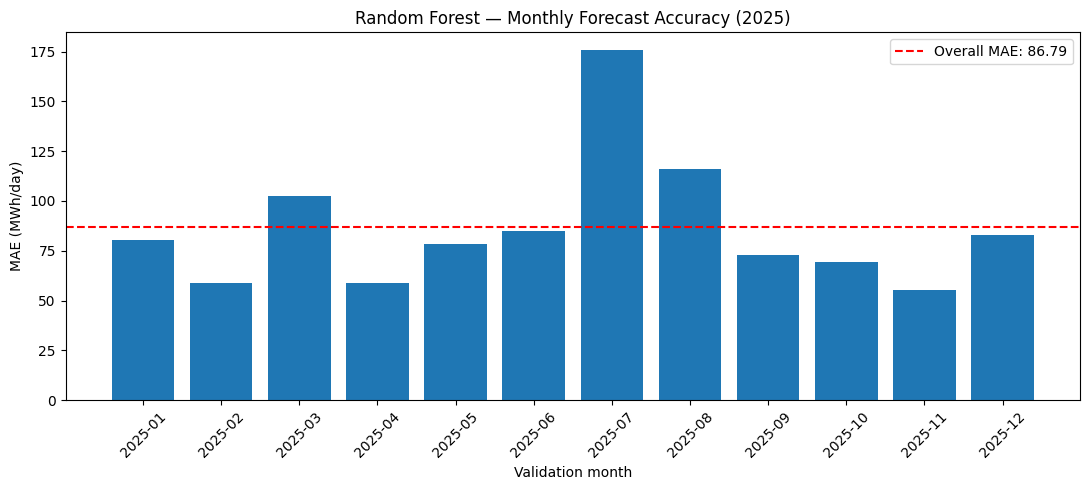

In [22]:
# Plot monthly MAE
fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    monthly_rf["validation_month"],
    monthly_rf["mae_mwh"]
)

ax.axhline(
    rf_metrics["mae_mwh"],
    color="red",
    linestyle="--",
    label=f"Overall MAE: {rf_metrics['mae_mwh']:.2f}"
)

ax.set_title("Random Forest — Monthly Forecast Accuracy (2025)")
ax.set_xlabel("Validation month")
ax.set_ylabel("MAE (MWh/day)")

ax.tick_params(axis="x", rotation=45)
ax.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "random_forest_monthly_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#### 7.3 Analyze overprediction

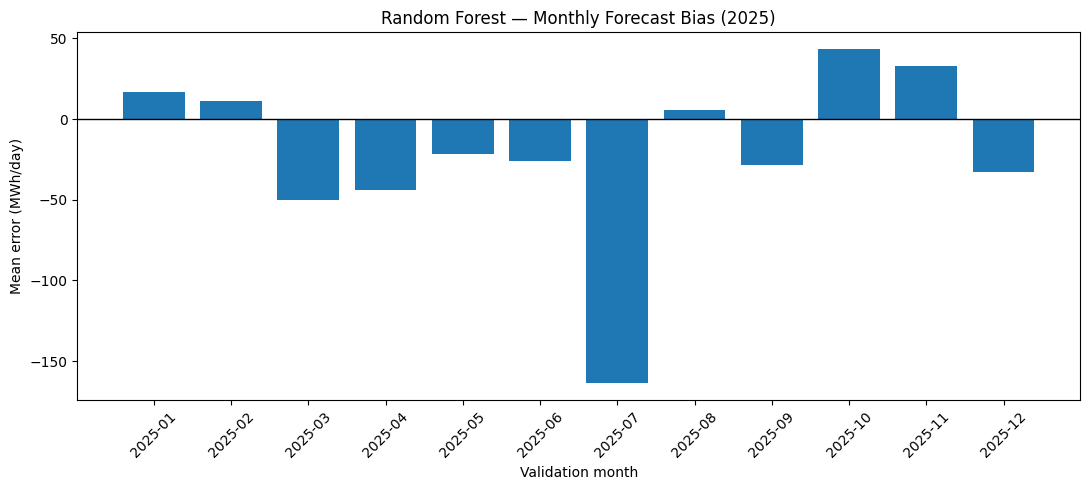

Overall mean error: -21.64 MWh/day
Months with overprediction: 7 out of 12


In [23]:
# Plot monthly mean prediction error
# Error = actual - predicted
# Negative values indicate overprediction

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    monthly_rf["validation_month"],
    monthly_rf["mean_error_mwh"]
)

ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.set_title("Random Forest — Monthly Forecast Bias (2025)")
ax.set_xlabel("Validation month")
ax.set_ylabel("Mean error (MWh/day)")

ax.tick_params(axis="x", rotation=45)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "random_forest_monthly_bias.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Overall mean error:",
    round(rf_metrics["mean_error_mwh"], 2),
    "MWh/day"
)

print(
    "Months with overprediction:",
    (monthly_rf["mean_error_mwh"] < 0).sum(),
    "out of 12"
)


#### 7.4 Save Random Forest predictions

In [30]:
# Export predictions using notebook 06 format

export_columns = [
    "date",
    "model",
    "validation_month",
    "actual_mwh",
    "predicted_mwh",
    "prediction_error_mwh",
    "absolute_error_mwh",
]

rf_pred[export_columns].to_csv(
    TABLE_DIR / "random_forest_validation.csv",
    index=False
)

print("Saved Random Forest validation predictions.")
print("Number of exported predictions:", len(rf_pred))


Saved Random Forest validation predictions.
Number of exported predictions: 365



## 8. Random Forest Hyperparameter Tuning

The initial Random Forest was evaluated using a fixed configuration. We now investigate whether a different model complexity improves its forecasting performance.

### Hyperparameters

We focus on two parameters:

- **`min_samples_leaf`:** The minimum number of training observations required in a terminal leaf. Larger values generally produce smoother predictions and reduce the ability of individual trees to fit small variations in the data.
- **`max_features`:** The proportion of available predictors considered at each split. Smaller values introduce greater variation among the trees.

We use a small, predefined parameter grid to limit computational complexity.

### Chronological tuning procedure

For each of the 12 monthly validation folds in 2025:

1. Select the eligible expanding training window using the same five-day availability assumption.
2. Divide that training window into five chronological inner cross-validation folds.
3. Exclude the four immediately preceding training rows from each inner validation block, ensuring an availability gap.
4. Fit preprocessing and Random Forest models using only the inner training observations.
5. Select the hyperparameters with the lowest average inner-validation MAE.
6. Refit the selected model using the entire eligible monthly training window.
7. Predict the corresponding month in 2025.

The inner cross-validation uses no observations from the outer validation month. The final 2026 test set remains untouched.

We compare the tuned Random Forest with the initial Random Forest within this notebook. The comprehensive comparison across model families is reserved for Notebook 10.


#### 8.1 define the hyperparameter search

In [31]:
# Hyperparameter grid for Random Forest

RF_PARAM_GRID = {
    "model__min_samples_leaf": [2, 6],
    "model__max_features": [0.7, 1.0],
}

# Use 120 trees during tuning to keep the search manageable.
# Each selected model will also be refitted with 120 trees.
TUNING_N_ESTIMATORS = 120

INNER_SPLITS = 5
INNER_GAP = MIN_LAG - 1

print("Hyperparameter combinations:", 4)
print("Inner CV folds:", INNER_SPLITS)
print("Gap between inner folds:", INNER_GAP, "rows")
print("Trees per Random Forest:", TUNING_N_ESTIMATORS)


Hyperparameter combinations: 4
Inner CV folds: 5
Gap between inner folds: 4 rows
Trees per Random Forest: 120


#### 8.2 Create the tuning function

In [32]:
def tune_random_forest(train):
    """
    Tune Random Forest using only eligible historical
    training observations.

    Returns:
        best_model: fitted Random Forest pipeline
        best_params: selected hyperparameters
        best_cv_mae: mean MAE across inner CV folds
    """

    train = train.sort_values("date").reset_index(drop=True)

    assert train["date"].is_unique

    inner_cv = TimeSeriesSplit(
        n_splits=INNER_SPLITS,
        gap=INNER_GAP
    )

    # Check that the row-based gap respects the
    # required calendar-date availability gap.
    for inner_train_idx, inner_valid_idx in inner_cv.split(train):

        last_training_date = train.loc[
            inner_train_idx[-1], "date"
        ]

        first_validation_date = train.loc[
            inner_valid_idx[0], "date"
        ]

        assert (
            first_validation_date - last_training_date
        ) >= pd.Timedelta(days=MIN_LAG), (
            "Inner CV violates the five-day availability rule."
        )

    pipeline = make_rf_pipeline()

    # Override the number of trees for the tuning experiment
    pipeline.set_params(
        model__n_estimators=TUNING_N_ESTIMATORS
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=RF_PARAM_GRID,
        scoring="neg_mean_absolute_error",
        cv=inner_cv,
        refit=True,
        n_jobs=1,
        error_score="raise"
    )

    search.fit(
        train[FEATURES],
        train[TARGET]
    )

    return (
        search.best_estimator_,
        search.best_params_,
        -search.best_score_
    )


#### 8.3 Run the tuned random forest on all 12 months

In [33]:
tuned_predictions = []
tuning_records = []

for month in VALIDATION_MONTHS:

    # Same expanding-window cutoff as the initial RF
    train, valid, cutoff = get_fold(month)

    # Hyperparameter search on historical training rows only
    best_model, best_params, best_cv_mae = (
        tune_random_forest(train)
    )

    # Forecast the outer validation month
    predicted = best_model.predict(valid[FEATURES])

    assert len(predicted) == len(valid)
    assert np.isfinite(predicted).all()

    fold_predictions = pd.DataFrame({
        "date": valid["date"].to_numpy(),
        "model": "random_forest_tuned_expanding",
        "validation_month": str(month),
        "actual_mwh": valid[TARGET].to_numpy(),
        "predicted_mwh": predicted,
    })

    tuned_predictions.append(fold_predictions)

    tuning_records.append({
        "validation_month": str(month),
        "training_cutoff": cutoff,
        "n_training_days": len(train),
        "best_min_samples_leaf":
            best_params["model__min_samples_leaf"],
        "best_max_features":
            best_params["model__max_features"],
        "inner_cv_mae_mwh": best_cv_mae,
    })

    print(
        f"{month} | "
        f"leaf={best_params['model__min_samples_leaf']} | "
        f"max_features={best_params['model__max_features']} | "
        f"inner CV MAE={best_cv_mae:.2f}"
    )

# Combine predictions from the 12 validation months
tuned_rf_pred = pd.concat(
    tuned_predictions,
    ignore_index=True
)

tuned_rf_pred["prediction_error_mwh"] = (
    tuned_rf_pred["actual_mwh"]
    - tuned_rf_pred["predicted_mwh"]
)

tuned_rf_pred["absolute_error_mwh"] = (
    tuned_rf_pred["prediction_error_mwh"].abs()
)

# Store monthly tuning decisions
tuning_table = pd.DataFrame(tuning_records)

# Verify identical evaluation coverage
assert len(tuned_rf_pred) == 365
assert tuned_rf_pred["date"].is_unique
assert set(tuned_rf_pred["date"]) == set(rf_pred["date"])

print("\nTuning completed successfully.")

display(tuning_table)


2025-01 | leaf=2 | max_features=0.7 | inner CV MAE=100.40
2025-02 | leaf=2 | max_features=0.7 | inner CV MAE=100.02
2025-03 | leaf=2 | max_features=0.7 | inner CV MAE=99.74
2025-04 | leaf=2 | max_features=0.7 | inner CV MAE=98.85
2025-05 | leaf=2 | max_features=0.7 | inner CV MAE=99.41
2025-06 | leaf=2 | max_features=0.7 | inner CV MAE=100.12
2025-07 | leaf=2 | max_features=0.7 | inner CV MAE=99.36
2025-08 | leaf=2 | max_features=0.7 | inner CV MAE=101.35
2025-09 | leaf=2 | max_features=0.7 | inner CV MAE=102.45
2025-10 | leaf=2 | max_features=0.7 | inner CV MAE=101.83
2025-11 | leaf=2 | max_features=0.7 | inner CV MAE=101.96
2025-12 | leaf=2 | max_features=0.7 | inner CV MAE=99.61

Tuning completed successfully.


,validation_month,training_cutoff,n_training_days,best_min_samples_leaf,best_max_features,inner_cv_mae_mwh
0,2025-01,2024-12-27,2553,2,0.7,100.395256
1,2025-02,2025-01-27,2584,2,0.7,100.022853
2,2025-03,2025-02-24,2612,2,0.7,99.735549
3,2025-04,2025-03-27,2643,2,0.7,98.853666
4,2025-05,2025-04-26,2673,2,0.7,99.409892
5,2025-06,2025-05-27,2704,2,0.7,100.124297
6,2025-07,2025-06-26,2734,2,0.7,99.358167
7,2025-08,2025-07-27,2765,2,0.7,101.345403
8,2025-09,2025-08-27,2796,2,0.7,102.448025
9,2025-10,2025-09-26,2826,2,0.7,101.832052


#### 8.4 Evaluate the tuned Random Forest

In [34]:
# Evaluate the tuned Random Forest on 2025

tuned_rf_metrics = compute_metrics(
    tuned_rf_pred["actual_mwh"],
    tuned_rf_pred["predicted_mwh"]
)

print("Tuned Random Forest — 2025 validation")
print("------------------------------------")

print(
    f"MAE: {tuned_rf_metrics['mae_mwh']:.2f} MWh/day"
)

print(
    f"RMSE: {tuned_rf_metrics['rmse_mwh']:.2f} MWh/day"
)

print(
    f"Mean error: "
    f"{tuned_rf_metrics['mean_error_mwh']:.2f} MWh/day"
)

# Compare only the two Random Forest versions
rf_versions = pd.DataFrame([
    {
        "model": "Initial Random Forest",
        **rf_metrics
    },
    {
        "model": "Tuned Random Forest",
        **tuned_rf_metrics
    }
])

display(rf_versions.round(2))

mae_change = (
    tuned_rf_metrics["mae_mwh"]
    - rf_metrics["mae_mwh"]
)

print(
    f"\nTuned minus initial MAE: "
    f"{mae_change:+.2f} MWh/day"
)

if mae_change < 0:
    print("The tuned model has lower validation MAE.")
elif mae_change > 0:
    print("The initial model has lower validation MAE.")
else:
    print("Both models have equal validation MAE.")


Tuned Random Forest — 2025 validation
------------------------------------
MAE: 87.24 MWh/day
RMSE: 115.99 MWh/day
Mean error: -21.73 MWh/day


,model,n_days,mae_mwh,rmse_mwh,mean_error_mwh
0,Initial Random Forest,365,86.79,115.27,-21.64
1,Tuned Random Forest,365,87.24,115.99,-21.73



Tuned minus initial MAE: +0.46 MWh/day
The initial model has lower validation MAE.


#### 8.5 Export the tuned Random Forest results

In [35]:
# Save tuned Random Forest predictions

export_columns = [
    "date",
    "model",
    "validation_month",
    "actual_mwh",
    "predicted_mwh",
    "prediction_error_mwh",
    "absolute_error_mwh",
]

tuned_rf_pred[export_columns].to_csv(
    TABLE_DIR / "random_forest_tuned_validation.csv",
    index=False
)

# Save parameter selections for reproducibility
tuning_table.to_csv(
    TABLE_DIR / "random_forest_tuning_results.csv",
    index=False
)

# Save model-specific validation metrics
rf_versions.to_csv(
    TABLE_DIR / "random_forest_versions_metrics.csv",
    index=False
)

print("Saved:")
print("- random_forest_tuned_validation.csv")
print("- random_forest_tuning_results.csv")
print("- random_forest_versions_metrics.csv")


Saved:
- random_forest_tuned_validation.csv
- random_forest_tuning_results.csv
- random_forest_versions_metrics.csv



## 9. Conclusion

This notebook evaluated Random Forest regression for forecasting next-day electricity consumption in Basel-Stadt.

Both Random Forest specifications were evaluated on the same 365 days of the 2025 validation period using 12 monthly expanding-window folds. All predictors were restricted to information permitted by the forecasting cutoff.

### Initial Random Forest

The initial Random Forest achieved:

- MAE: **86.79 MWh/day**
- RMSE: **115.27 MWh/day**
- Mean signed error: **−21.64 MWh/day**

The negative mean signed error indicates that the model overpredicted electricity consumption on average.

Forecasting accuracy varied across months. July had the highest MAE (175.90 MWh/day), while November had the lowest (55.32 MWh/day).

### Hyperparameter tuning

Random Forest hyperparameters were selected through five-fold chronological cross-validation within each eligible monthly training window.

The selected configuration was consistent across all 12 months:

- `min_samples_leaf = 2`
- `max_features = 0.7`

The tuned model achieved:

- MAE: **87.24 MWh/day**
- RMSE: **115.99 MWh/day**
- Mean signed error: **−21.73 MWh/day**

The tuned model performed slightly worse than the initial specification on the 2025 validation period.

Since the initial model used 300 trees and the tuned model used 120, the difference in performance cannot be attributed exclusively to the tuned parameters.

### Interpretation

These findings show that Random Forest provides a viable nonlinear forecasting approach, but the chosen tuning procedure did not improve its validation accuracy.

The negative mean errors suggest a tendency to overpredict electricity consumption, particularly during certain months.

A possible explanation is that the expanding training window includes older periods with different electricity consumption levels. However, this hypothesis cannot be established from the present analysis.

Notebook 08 will investigate whether replacing the expanding window with a rolling three-year training window improves forecasting accuracy and reduces systematic prediction bias.

The 2026 holdout has not been used for model selection or evaluation.
